In [621]:
'''import numpy as np


def sparse_nmf(
    V,
    n_components,
    *,
    W_init=None,
    H_init=None,
    lambda_sparse=0.1,
    g=None,
    g_prime=None,
    max_iter=500,
    tol=1e-5,
    eps=1e-10,
    random_state=None,
    return_history=False,
):
    """
    Sparse NMF using the multiplicative updates in equations (14) and (18).

    Parameters
    ----------
    V : array-like, shape (n_features, n_samples)
        Nonnegative input matrix. Each column is one sample.
    n_components : int
        Number of basis vectors.
    W_init : array-like, shape (n_features, n_components), optional
        Initial nonnegative basis matrix.
    H_init : array-like, shape (n_components, n_samples), optional
        Initial nonnegative activation matrix.
    lambda_sparse : float
        Sparsity regularization coefficient, lambda >= 0.
    g : callable, optional
        Elementwise sparsity penalty. Default: g(h) = h.
    g_prime : callable, optional
        Elementwise derivative of g. Default: g'(h) = 1.
        If a custom g is provided, g_prime must also be provided.
    max_iter : int
        Maximum number of iterations.
    tol : float
        Relative objective-change tolerance for stopping.
    eps : float
        Small positive constant for numerical stability.
    random_state : int, optional
        Random seed for initialization.
    return_history : bool
        If True, also return objective values and their components.

    Returns
    -------
    W : ndarray, shape (n_features, n_components)
        L2-normalized basis matrix.
    H : ndarray, shape (n_components, n_samples)
        Activation matrix.
    history : list of dicts, optional
        Returned only when return_history=True.

    Notes
    -----
    The returned matrices satisfy the reconstruction convention
        V_hat = W @ H
    with L2-normalized columns of W.
    """

    V = np.asarray(V, dtype=np.float64)

    if V.ndim != 2:
        raise ValueError("V must be a 2D matrix.")
    if not np.all(np.isfinite(V)) or np.any(V < 0):
        raise ValueError("V must contain finite, nonnegative values.")
    if not isinstance(n_components, (int, np.integer)) or n_components < 1:
        raise ValueError("n_components must be a positive integer.")
    if lambda_sparse < 0:
        raise ValueError("lambda_sparse must be nonnegative.")
    if max_iter < 1:
        raise ValueError("max_iter must be at least 1.")
    if tol < 0 or eps <= 0:
        raise ValueError("tol must be nonnegative and eps must be positive.")
    if (g is None) != (g_prime is None):
        raise ValueError("Provide both g and g_prime, or neither.")

    # Default: linear sparsity penalty, g(h) = h.
    if g is None:
        g = lambda h: h
        g_prime = lambda h: np.ones_like(h)

    n_features, n_samples = V.shape
    rng = np.random.default_rng(random_state)

    # Initialize W.
    if W_init is None:
        W = rng.random((n_features, n_components)) + eps
    else:
        W = np.asarray(W_init, dtype=np.float64).copy()
        if W.shape != (n_features, n_components):
            raise ValueError("W_init has an incorrect shape.")
        if not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError("W_init must be finite and nonnegative.")
        W = np.maximum(W, eps)

    # Initialize H.
    if H_init is None:
        H = rng.random((n_components, n_samples)) + eps
    else:
        H = np.asarray(H_init, dtype=np.float64).copy()
        if H.shape != (n_components, n_samples):
            raise ValueError("H_init has an incorrect shape.")
        if not np.all(np.isfinite(H)) or np.any(H < 0):
            raise ValueError("H_init must be finite and nonnegative.")
        H = np.maximum(H, eps)

    def elementwise(func, X, name):
        """Evaluate a penalty or derivative elementwise."""
        result = np.asarray(func(X), dtype=np.float64)

        try:
            result = np.broadcast_to(result, X.shape)
        except ValueError as exc:
            raise ValueError(
                f"{name} must return a scalar or an array "
                "broadcastable to the shape of H."
            ) from exc

        if not np.all(np.isfinite(result)):
            raise ValueError(f"{name} returned non-finite values.")

        return result

    def evaluate_objective(W_bar, H):
        """Objective: 0.5 * ||V - W_bar H||_F^2 + lambda * sum(g(H))."""
        R = W_bar @ H
        reconstruction_loss = 0.5 * np.sum((V - R) ** 2)

        penalty = elementwise(g, H, "g")
        if np.any(penalty < 0):
            raise ValueError("g(H) must be nonnegative.")

        sparsity_loss = lambda_sparse * np.sum(penalty)
        return reconstruction_loss + sparsity_loss, reconstruction_loss, sparsity_loss

    history = []
    previous_loss = None

    for iteration in range(1, max_iter + 1):

        # ---------------------------------------------------------
        # Steps 1-3:
        # Compute the gradient of each basis norm, normalize W,
        # and reconstruct V.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        # For the L2 norm: grad_W ||W_j||_2 = W_j / ||W_j||_2.
        grad_norm = W_bar

        R = W_bar @ H

        # ---------------------------------------------------------
        # Step 4: update H using equation (14).
        #
        # H[j, i] <- H[j, i] *
        #   (W_bar[:, j]^T V[:, i]) /
        #   (W_bar[:, j]^T R[:, i] + lambda * g'(H[j, i]))
        # ---------------------------------------------------------
        sparse_gradient = elementwise(g_prime, H, "g_prime")
        if np.any(sparse_gradient < 0):
            raise ValueError(
                "g_prime(H) must be nonnegative for this multiplicative update."
            )

        H_num = W_bar.T @ V
        H_den = W_bar.T @ R + lambda_sparse * sparse_gradient

        H *= H_num / np.maximum(H_den, eps)
        H = np.maximum(H, eps)

        # ---------------------------------------------------------
        # Step 5: reconstruct using the updated activations.
        # ---------------------------------------------------------
        R = W_bar @ H

        # ---------------------------------------------------------
        # Step 6: update the non-normalized W using equation (18).
        #
        # W_j <- W_j * numerator_j / denominator_j
        #
        # All components are updated simultaneously.
        # ---------------------------------------------------------
        proj_R = W_bar.T @ R
        proj_V = W_bar.T @ V

        # Scalar sums over samples i, one value per component j.
        weighted_R_proj = np.sum(H * proj_R, axis=1)[None, :]
        weighted_V_proj = np.sum(H * proj_V, axis=1)[None, :]

        W_num = V @ H.T + grad_norm * weighted_R_proj
        W_den = R @ H.T + grad_norm * weighted_V_proj

        W *= np.maximum(W_num, 0.0) / np.maximum(W_den, eps)
        W = np.maximum(W, eps)

        # ---------------------------------------------------------
        # Evaluate convergence using the updated basis directions.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        loss, rec_loss, sparse_loss = evaluate_objective(W_bar, H)

        if previous_loss is None:
            relative_change = None
        else:
            relative_change = (
                abs(previous_loss - loss) / max(abs(previous_loss), eps)
            )

        history.append({
            "iteration": iteration,
            "loss": loss,
            "reconstruction_loss": rec_loss,
            "sparsity_penalty": sparse_loss,
            "relative_change": relative_change,
        })

        if previous_loss is not None and relative_change < tol:
            break

        previous_loss = loss

    # Return normalized bases, consistent with the reconstruction in step 3.
    W_final = W / np.maximum(np.linalg.norm(W, axis=0), eps)[None, :]

    if return_history:
        return W_final, H, history

    return W_final, H'''
import numpy as np
np.random.seed(42)
def sparse_nmf(
    V,
    n_components,
    *,
    W_init=None,
    H_init=None,
    lambda_sparse=0.1,
    lambda_vol=2.0,
    g=None,
    g_prime=None,
    max_iter=500,
    tol=1e-5,
    eps=1e-10,
    random_state=None,
    return_history=False,
):
    """
    Sparse NMF with signed volume regularization.

    Objective
    ---------
        min_{W,H >= 0}
            0.5 * ||V - W_bar @ H||_F^2
            + lambda_sparse * sum(g(H))
            + 0.5 * lambda_vol
                * logdet(W_bar.T @ W_bar + eps * I)

    where W_bar contains L2-normalized columns of W.

    Parameters
    ----------
    V : array-like, shape (n_features, n_samples)
        Nonnegative input matrix.

    n_components : int
        Number of basis vectors.

    W_init : array-like, optional
        Initial basis matrix, shape (n_features, n_components).

    H_init : array-like, optional
        Initial activation matrix, shape (n_components, n_samples).

    lambda_sparse : float
        Nonnegative sparsity regularization coefficient.

    lambda_vol : float
        Signed volume regularization coefficient:
            > 0 : minimum-volume regularization
            = 0 : original sparse NMF algorithm
            < 0 : maximum-volume regularization

    g : callable, optional
        Elementwise sparsity penalty. Default: g(h) = h.

    g_prime : callable, optional
        Elementwise derivative of g. Default: g'(h) = 1.
        If g is supplied, g_prime must also be supplied.

    max_iter : int
        Maximum number of iterations.

    tol : float
        Relative objective-change tolerance.

    eps : float
        Numerical-stability constant. Also regularizes the
        Gram matrix in the volume term when lambda_vol != 0.

    random_state : int, optional
        Random seed.

    return_history : bool
        If True, return the objective history.

    Returns
    -------
    W_final : ndarray, shape (n_features, n_components)
        L2-normalized basis matrix.

    H : ndarray, shape (n_components, n_samples)
        Activation matrix.

    history : list of dicts, optional
        Returned only when return_history=True.

    Notes
    -----
    When lambda_vol == 0, the original multiplicative updates,
    objective, and convergence calculation are retained.

    For nonzero lambda_vol, the W update incorporates the
    projected gradient of the signed log-determinant regularizer
    and uses backtracking to accept only non-increasing
    objective steps.
    """

    V = np.asarray(V, dtype=np.float64)

    if V.ndim != 2:
        raise ValueError("V must be a 2D matrix.")

    if not np.all(np.isfinite(V)) or np.any(V < 0):
        raise ValueError("V must contain finite, nonnegative values.")

    if not isinstance(n_components, (int, np.integer)) \
            or n_components < 1:
        raise ValueError("n_components must be a positive integer.")

    if lambda_sparse < 0 or not np.isfinite(lambda_sparse):
        raise ValueError("lambda_sparse must be finite and nonnegative.")

    if not np.isfinite(lambda_vol):
        raise ValueError("lambda_vol must be finite.")

    if max_iter < 1:
        raise ValueError("max_iter must be at least 1.")

    if tol < 0 or eps <= 0:
        raise ValueError("tol must be nonnegative and eps must be positive.")

    if (g is None) != (g_prime is None):
        raise ValueError("Provide both g and g_prime, or neither.")

    # Default sparsity penalty.
    if g is None:
        g = lambda h: h
        g_prime = lambda h: np.ones_like(h)

    n_features, n_samples = V.shape
    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Initialize W.
    # ---------------------------------------------------------
    if W_init is None:
        W = rng.random((n_features, n_components)) + eps
    else:
        W = np.asarray(W_init, dtype=np.float64).copy()

        if W.shape != (n_features, n_components):
            raise ValueError("W_init has an incorrect shape.")

        if not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError("W_init must be finite and nonnegative.")

        W = np.maximum(W, eps)

    # ---------------------------------------------------------
    # Initialize H.
    # ---------------------------------------------------------
    if H_init is None:
        H = rng.random((n_components, n_samples)) + eps
    else:
        H = np.asarray(H_init, dtype=np.float64).copy()

        if H.shape != (n_components, n_samples):
            raise ValueError("H_init has an incorrect shape.")

        if not np.all(np.isfinite(H)) or np.any(H < 0):
            raise ValueError("H_init must be finite and nonnegative.")

        H = np.maximum(H, eps)

    def elementwise(func, X, name):
        result = np.asarray(func(X), dtype=np.float64)

        try:
            result = np.broadcast_to(result, X.shape)
        except ValueError as exc:
            raise ValueError(
                f"{name} must return a scalar or an array "
                "broadcastable to the shape of H."
            ) from exc

        if not np.all(np.isfinite(result)):
            raise ValueError(f"{name} returned non-finite values.")

        return result

    def volume_value_and_gradient(W_bar):
        """
        R_vol = 0.5 * logdet(W_bar.T @ W_bar + eps * I).

        Gradient with respect to W_bar:
            W_bar @ inv(W_bar.T @ W_bar + eps * I)
        """
        gram = W_bar.T @ W_bar
        gram.flat[::n_components + 1] += eps

        sign, logdet = np.linalg.slogdet(gram)

        if sign <= 0 or not np.isfinite(logdet):
            raise FloatingPointError(
                "Invalid log-determinant of the regularized Gram matrix."
            )

        volume = 0.5 * logdet

        # Avoid explicitly calculating the matrix inverse.
        inv_gram = np.linalg.solve(
            gram,
            np.eye(n_components),
        )

        gradient = W_bar @ inv_gram

        # Project onto the tangent space of the unit-L2 spheres.
        # Radial changes disappear when W is normalized.
        radial = np.sum(
            W_bar * gradient,
            axis=0,
            keepdims=True,
        )

        gradient -= W_bar * radial

        return volume, gradient

    def evaluate_objective(W_bar, H):
        R = W_bar @ H

        reconstruction_loss = 0.5 * np.sum((V - R) ** 2)

        penalty = elementwise(g, H, "g")

        if np.any(penalty < 0):
            raise ValueError("g(H) must be nonnegative.")

        sparsity_loss = lambda_sparse * np.sum(penalty)

        # Preserve the original objective exactly when lambda_vol == 0.
        if lambda_vol == 0.0:
            return (
                reconstruction_loss + sparsity_loss,
                reconstruction_loss,
                sparsity_loss,
                0.0,
            )

        volume, _ = volume_value_and_gradient(W_bar)
        volume_penalty = lambda_vol * volume

        loss = (
            reconstruction_loss
            + sparsity_loss
            + volume_penalty
        )

        return loss, reconstruction_loss, sparsity_loss, volume

    history = []
    previous_loss = None

    for iteration in range(1, max_iter + 1):

        # ---------------------------------------------------------
        # 1. Normalize W and reconstruct.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        grad_norm = W_bar

        R = W_bar @ H

        # ---------------------------------------------------------
        # 2. Update H using the original sparse multiplicative rule.
        # ---------------------------------------------------------
        sparse_gradient = elementwise(g_prime, H, "g_prime")

        if np.any(sparse_gradient < 0):
            raise ValueError(
                "g_prime(H) must be nonnegative for this "
                "multiplicative update."
            )

        H_num = W_bar.T @ V
        H_den = W_bar.T @ R + lambda_sparse * sparse_gradient

        H *= H_num / np.maximum(H_den, eps)
        H = np.maximum(H, eps)

        # ---------------------------------------------------------
        # 3. Reconstruct using updated H.
        # ---------------------------------------------------------
        R = W_bar @ H

        # ---------------------------------------------------------
        # 4. Construct the original W multiplicative update.
        # ---------------------------------------------------------
        proj_R = W_bar.T @ R
        proj_V = W_bar.T @ V

        weighted_R_proj = np.sum(
            H * proj_R, axis=1
        )[None, :]

        weighted_V_proj = np.sum(
            H * proj_V, axis=1
        )[None, :]

        W_num = (
            V @ H.T
            + grad_norm * weighted_R_proj
        )

        W_den = (
            R @ H.T
            + grad_norm * weighted_V_proj
        )

        # ---------------------------------------------------------
        # 5. Original algorithm: retain exactly the original W step.
        # ---------------------------------------------------------
        if lambda_vol == 0.0:

            W *= (
                np.maximum(W_num, 0.0)
                / np.maximum(W_den, eps)
            )

            W = np.maximum(W, eps)

        else:
            # -----------------------------------------------------
            # Signed volume gradient.
            #
            # For positive lambda_vol, minimize log-volume.
            # For negative lambda_vol, maximize log-volume.
            # -----------------------------------------------------
            _, grad_volume = volume_value_and_gradient(W_bar)

            signed_gradient = lambda_vol * grad_volume

            # Existing multiplicative updates represent the gradient
            # as denominator - numerator.
            #
            # Add positive gradient entries to the denominator,
            # and negative gradient entries to the numerator.
            W_num_vol = np.maximum(-signed_gradient, 0.0)
            W_den_vol = np.maximum(signed_gradient, 0.0)

            W_num_total = (
                np.maximum(W_num, 0.0) + W_num_vol
            )

            W_den_total = (
                np.maximum(W_den, eps) + W_den_vol
            )

            W_candidate = W * (
                W_num_total / W_den_total
            )

            W_candidate = np.maximum(W_candidate, eps)

            # -----------------------------------------------------
            # Backtracking: accept only if the complete objective
            # does not increase, with H held fixed.
            # -----------------------------------------------------
            old_W = W.copy()

            base_loss, *_ = evaluate_objective(W_bar, H)

            alpha = 1.0
            accepted = False

            for _ in range(30):

                W_trial = old_W + alpha * (
                    W_candidate - old_W
                )

                W_trial = np.maximum(W_trial, eps)

                trial_norms = np.linalg.norm(W_trial, axis=0)

                W_trial_bar = W_trial / np.maximum(
                    trial_norms, eps
                )[None, :]

                trial_loss, *_ = evaluate_objective(
                    W_trial_bar, H
                )

                tolerance = 1e-12 * max(1.0, abs(base_loss))

                if (
                    np.isfinite(trial_loss)
                    and trial_loss <= base_loss + tolerance
                ):
                    W = W_trial
                    accepted = True
                    break

                alpha *= 0.5

            if not accepted:
                # Keep the previous basis if no candidate step succeeds.
                W = old_W

        # ---------------------------------------------------------
        # 6. Evaluate convergence using normalized basis directions.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        (
            loss,
            rec_loss,
            sparse_loss,
            volume,
        ) = evaluate_objective(W_bar, H)

        if previous_loss is None:
            relative_change = None
        else:
            relative_change = (
                abs(previous_loss - loss)
                / max(abs(previous_loss), eps)
            )

        entry = {
            "iteration": iteration,
            "loss": loss,
            "reconstruction_loss": rec_loss,
            "sparsity_penalty": sparse_loss,
            "relative_change": relative_change,
        }

        # Keep the original history schema when lambda_vol == 0.
        if lambda_vol != 0.0:
            entry["log_volume"] = volume
            entry["volume_penalty"] = lambda_vol * volume

        history.append(entry)

        if previous_loss is not None and relative_change < tol:
            break

        previous_loss = loss

    W_final = W / np.maximum(
        np.linalg.norm(W, axis=0), eps
    )[None, :]

    if return_history:
        return W_final, H, history

    return W_final, H

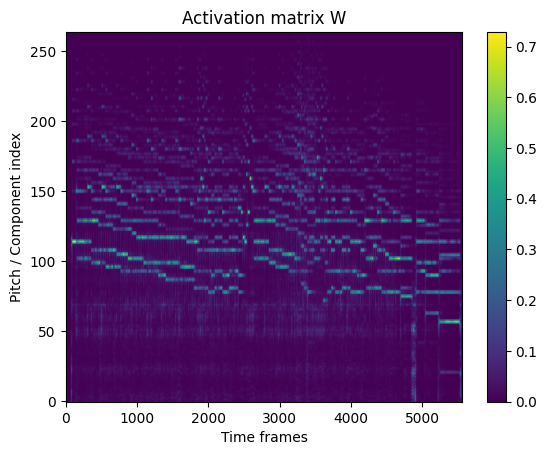

In [622]:
from scipy.io import wavfile
import librosa
import numpy as np
K = 3
HOP = 1024
file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
g = 2
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP, sparsity=0.05))
#spectrogram_1 = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP))
onsets = librosa.onset.onset_detect(y=x, sr=f_s, hop_length=HOP,units='frames')
K = 3
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
spectrogram = norm_log(spectrogram, g)
spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)

import matplotlib.pyplot as plt
plt.figure()
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [623]:
def W_norm(W):
  W_c = W.copy()
  for i in range(W.shape[1]):
    W_c[:,i] = W_c[:,i]/np.sum(W[:,i])
  return W_c

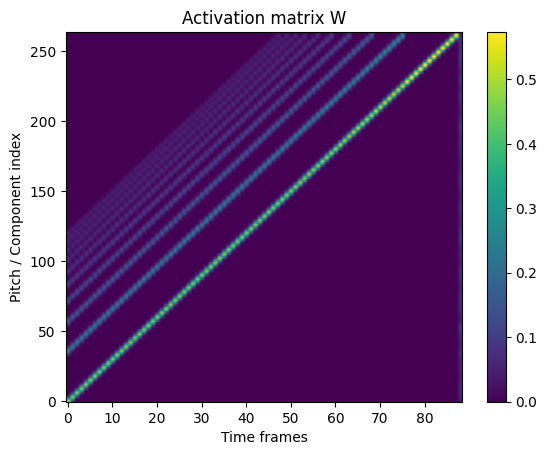

In [624]:
def build_W0(
    sr,
    bins_per_octave,
    n_bins,
    fmin,
    n_harmonics=10,
    decay=1.0,
    sigma=1.5,
    inharmonicity=0.0,
):
    # CQT frequency grid: must match your spectrogram
    freqs = librosa.cqt_frequencies(
        n_bins=n_bins,
        fmin=fmin,
        bins_per_octave=bins_per_octave,
    )

    # Log-frequency coordinates corresponding to CQT bins
    log_freqs = np.log2(freqs)
    k = np.arange(n_bins, dtype=float)

    # Piano pitches: MIDI 21 (A0) through MIDI 108 (C8)
    midi_notes = np.arange(21, 109)

    W0 = np.zeros((n_bins, len(midi_notes)), dtype=float)

    f_max = min(freqs[-1], sr / 2.0)

    for i, m in enumerate(midi_notes):
        f0 = librosa.midi_to_hz(m)
        template = np.zeros(n_bins, dtype=float)

        for h in range(1, n_harmonics + 1):

            # Harmonic frequency, optionally including piano
            # string inharmonicity.
            fh = h * f0 * np.sqrt(
                (1.0 + inharmonicity * h**2)
                / (1.0 + inharmonicity)
            )

            # CRITICAL FIX:
            # Never map out-of-range harmonics onto the
            # first or last CQT bin.
            if fh >= f_max:
                break

            if fh < freqs[0]:
                continue

            # Fractional bin coordinate in log-frequency space
            center = np.interp(
                np.log2(fh),
                log_freqs,
                k,
            )

            # Gaussian harmonic peak
            peak = np.exp(
                -0.5 * ((k - center) / sigma) ** 2
            )

            template += peak / (h ** decay)

        # L2 normalization
        norm = np.linalg.norm(template)
        if norm > 1e-10:
            template /= norm

        W0[:, i] = template

    return W0

def build_noise_basis(n_bins, n_components=2):
    Wn = np.zeros((n_bins, n_components))

    for i in range(n_components):
        # random smooth noise shape
        x = np.random.rand(n_bins)
        x = np.convolve(x, np.hanning(15), mode='same')
        x /= np.linalg.norm(x) + 1e-10
        Wn[:, i] = x

    return Wn
W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'), sigma=1.75)
#W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'), sigma=2.0)
Wn = build_noise_basis(88*K, 1)
W_0 = np.concatenate([W_0, Wn], axis=1)
#W_0 = W_norm(W_0)
#print(W_0.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_0, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [625]:
print(np.sum(W_0[:,40]))

5.852066211129638


In [626]:
# V.shape = (n_frequency_bins, n_frames)
#H_0 = np.random((88,spectrogram.shape[1]))

W, H, history = sparse_nmf(
    spectrogram,
    W_init=W_0,
    n_components=88+1,
    lambda_sparse=1e-3,
    max_iter=500,
    tol=1e-5,
    random_state=42,
    return_history=True,
)

V_hat = W @ H

print("W:", W.shape)
print("H:", H.shape)
print("Reconstruction:", V_hat.shape)
print("Iterations:", len(history))
print("Final objective:", history[-1]["loss"])

W: (264, 89)
H: (89, 5562)
Reconstruction: (264, 5562)
Iterations: 500
Final objective: -22.947333341811373


In [627]:
print(np.sum(W[:,40]))
print((W[120,40]+W[121,40]+W[122,40])/np.sum(W[:,40]))

4.0415780670086825
0.1422588387581907


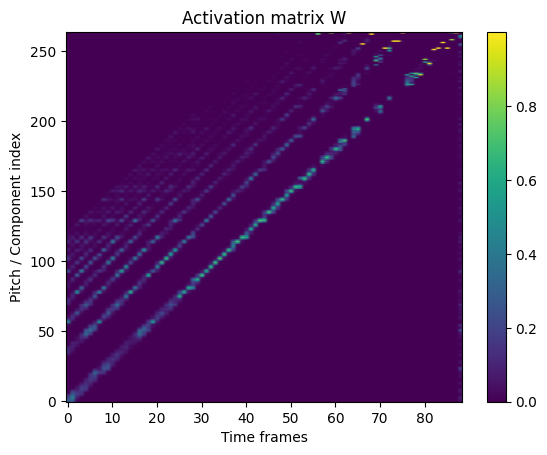

In [628]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [629]:
def reform_W(W_n, t):
  l = []
  for i in range(88):
    s = W_n[i*3,i]+W_n[i*3+1,i]+W_n[i*3+2,i]
    s = s / np.sum(W_n[:,i])
    #print(s)
    if(s>t):
      #for j in range(264):
        #W_c[j,i] = W_n[j,i]
      l.append(i)
  print(l)
  #W_c = W_0[:,l]
  W_c = W_n[:,l]
  return (W_c,l)

In [630]:
(W_n, l) = reform_W(W,0.2)

[19, 25, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 57, 58, 60, 62, 64, 65, 67, 70, 72, 76, 77, 78, 80, 86, 87]


In [631]:
Wa = build_noise_basis(88*K, 1)
W_n = np.concatenate([W_n, Wa], axis=1)
#W_n = np.concatenate([W, Wa], axis=1)
#W_n = W_norm(W_n)

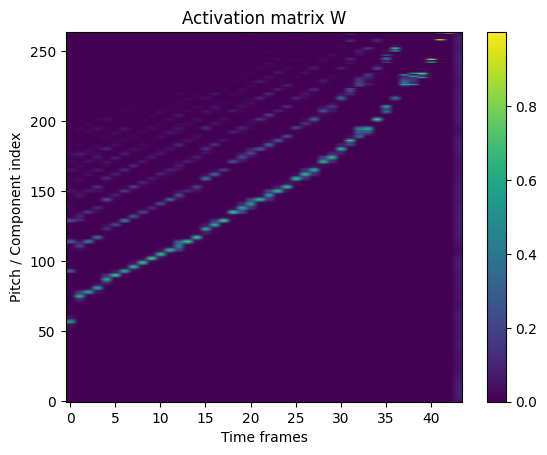

In [632]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_n, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [633]:
print(W_n.shape[1])

44


In [634]:
# V.shape = (n_frequency_bins, n_frames)
#H_0 = np.random((88,spectrogram.shape[1]))

W, H, history = sparse_nmf(
    spectrogram,
    W_init=W_n,
    n_components=W_n.shape[1],
    lambda_sparse=1e-3,
    max_iter=500,
    tol=1e-5,
    random_state=42,
    return_history=True,
)

V_hat = W @ H

print("W:", W.shape)
print("H:", H.shape)
print("Reconstruction:", V_hat.shape)
print("Iterations:", len(history))
print("Final objective:", history[-1]["loss"])

W: (264, 44)
H: (44, 5562)
Reconstruction: (264, 5562)
Iterations: 83
Final objective: 125.03778069787738


In [ ]:
print(H.shape)

In [ ]:
#print(H_r.shape)

In [ ]:
H_r = np.zeros((88,H.shape[1]))
for m in range(len(l)):
  H_r[l[m],:] = H[m,:]
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H_r, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
import scipy
from scipy.ndimage import label
def med_filter(X, sz=5):
  X_r = np.zeros(X.shape)
  for i in range(X.shape[0]):
    X_r[i,:] = scipy.ndimage.median_filter(X[i,:], size=sz, cval=0, mode='constant')
  return X_r

def enforce_min_duration(B, min_len=10):
    for q in range(B.shape[0]):
        labels, n = label(B[q])
        for i in range(1, n+1):
            if np.sum(labels == i) < min_len:
                B[q][labels == i] = 0
    return B
H1 = med_filter(H_r)
#H1 = med_filter(H)
H2 = np.zeros_like(H1)
idx = np.argpartition(H1, -10, axis=0)[-10:, :]
H2[idx, np.arange(H1.shape[1])] = H1[idx, np.arange(H1.shape[1])]
H3 = med_filter(H2)
t = H3.max() * 0.2
H4 = (H3 > t).astype(int)
H5 = enforce_min_duration(H4,min_len=15)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H5, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
pip install pretty_midi

In [ ]:
import numpy as np
import pretty_midi

def midi_to_binary_matrix(
    midi_input,
    dt=0.02,                     # time quantum in seconds
    pitch_range=(21, 108),  # A0–C8 by default
    min_overlap=0.5         # fraction of frame that must be covered
):
    """
    Convert MIDI to binary (88 x T) note activation matrix using fixed time grid.

    A note is active in a frame if it overlaps the frame
    by at least min_overlap * dt.
    """

    if dt <= 0:
        raise ValueError("dt must be positive (seconds)")

    # Load MIDI
    if isinstance(midi_input, pretty_midi.PrettyMIDI):
        pm = midi_input
    else:
        pm = pretty_midi.PrettyMIDI(midi_input)

    # Time axis
    total_time = pm.get_end_time()
    T = int(np.ceil(total_time / dt))
    frame_times = np.arange(T) * dt

    n_pitches = pitch_range[1] - pitch_range[0] + 1
    B = np.zeros((n_pitches, T), dtype=np.uint8)

    # Process notes
    for instrument in pm.instruments:
        if instrument.is_drum:
            continue

        for note in instrument.notes:
            if not (pitch_range[0] <= note.pitch <= pitch_range[1]):
                continue

            p = note.pitch - pitch_range[0]

            start_frame = int(np.floor(note.start / dt))
            end_frame   = int(np.ceil(note.end   / dt))

            for t in range(start_frame, min(end_frame, T)):
                frame_start = t * dt
                frame_end   = frame_start + dt

                overlap = max(
                    0.0,
                    min(note.end, frame_end) - max(note.start, frame_start)
                )

                if overlap >= min_overlap * dt:
                    B[p, t] = 1

    return B, frame_times

In [ ]:
# 20 ms frames (matches typical STFT hop ~512 @ 44.1kHz)
dt = 1024 / f_s
B, times = midi_to_binary_matrix(
    "Prelude-in-E-Minor-Nr-4.mid",
    dt=dt
)
print(B.shape,H4.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(B, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [643]:
def evaluate_results(H_et,H):
  #H_et - reference transcription of the piece
  #H - estimated transcription of the piece
  assert H_et.shape == H.shape
  P = 0
  R = 0
  F1 = 0
  TP = 0
  FP = 0
  FN = 0
  for i in range(H_et.shape[1]):
    TP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 1)
    FP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 0 and p == 1)
    FN += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 0)
  P = TP / (TP + FP)
  R = TP / (TP + FN)
  F1 = 2 * P * R / (P + R)
  return (P,R,F1)

In [644]:
print(H5.shape)

(88, 5562)


In [645]:
print(evaluate_results(H5[:,:B.shape[1]],B))

(0.6741777356103732, 0.4855369547887484, 0.5645150612380007)
